# N139 interpretation

The first two authorized steps are complete: larger-support probe robustness
and a screen of one unlabeled aligned-feature retention candidate. Fourteen
saved encoder states were evaluated without SSL training; duplicate encoder
states were excluded from regression. Five targeted tests and independent
reconstruction of all 168 saved conditions pass. N137 remains stopped.

## Larger support sets do not produce a modern accuracy gain

On the common 7,044 modern queries, N137 conservative versus its parent changes
balanced accuracy by -0.516 pp at fifty labels, -0.307 pp at one hundred, and
-0.411 pp at two hundred. The corresponding marginal paired-query intervals
are [-0.861,-0.140], [-0.692,+0.102], and [-0.936,+0.138]. The hundred/two-hundred
results do not establish a decline, but none establishes an improvement.

Every larger-support comparison uses four disjoint pools, with 24 nested draws
per pool at fifty/hundred labels and one full draw per pool at two hundred.
Support labels are offline evaluation only. Eight hundred images are enrolled
across the four pools and excluded from all modern query evaluations.

Absolute accuracy improves with support size: parent 60.869% to 64.339%,
conservative 60.353% to 63.928% between fifty and two-hundred labels. More
labels help both models; the adapted encoder does not overtake the parent.
The primary two-hundred-label pool changes are -0.349,+0.026,+0.273,-1.594 pp.
Support-population sensitivity remains; query intervals hold these pools fixed.

The historical query population still favors adaptation. With these SAME new
modern support pools, the conservative model gains +1.813 pp at two-hundred
labels on historical queries. Archived N101 gains +1.000 pp there but loses
0.918 pp on modern queries. Population dependence therefore persists after
increasing support and balancing the support pools; the old gains cannot be
explained only by fifty-label reader noise.

Modern class/light tradeoffs also persist. At two hundred labels, N137 changes
day-city/day-highway/night-city/night-highway accuracy by
+1.030/-2.162/-4.571/+4.060 pp. Its worst absolute cell accuracy improves from
52.781% to 55.102%, even while night-city loses 4.571 pp. Absolute worst-cell
accuracy and maximum cell-specific deterioration are different quantities;
neither should substitute for the other in a retention objective.

## Aligned feature recovery does not qualify as a controller objective

The unlabeled scorer works numerically. Its parent recovery error is 0.000571;
rotation/scale/translation invariance error is 1.1e-18; shuffled-row error
increases by 1.081. It reads no task labels, clip boundaries or future images.
Bank folds and support/query exclusions are intact.

The task relationship is weak. Across twelve unique non-parent states, the
rank correlation with maximum class/light deterioration is about 0.112.
Adding the signal to dose features reduces held-group MSE from 10.193 to
7.910 (22.4%), but the simple mean forecast already achieves 8.116: the
increment over that baseline is only 2.5%, below the locked 10% requirement.
Two of five held groups worsen relative to dose. Coefficients are positive
in all five folds, which is encouraging directionally but insufficient.

The calibration population also fails the required outcome coverage: every
unique adapted state loses at least 4.338 pp in one task cell; there are no
near-benign states at <=1 pp loss. This screen cannot establish discrimination
between harmless and harmful adaptation. It is an exploratory held-state
association test, not online update forecasting or counterfactual action ranking.

Consequently the retention-controlled training branch is not launched. The
predeclared scientific gates failed; this is not a permission or infrastructure
block. The result does not prove that all unlabeled retention signals are
useless, but it does not support adding this score to an MPC objective.

## Implication for subsequent work

Keep conservative low-dose N101-style control as the stronger empirical starting
point, with frozen parent and dose-matched random controls. Before a new long
run, collect a small controlled calibration set containing both near-benign
and materially harmful updates under paired continuations. A candidate must
predict incremental task damage beyond dose/mean on those contrasts. Retention
must be checked by task cell, as an improving worst absolute cell can hide
loss in another cell.

If generic feature recovery is replaced by recovery of task-directed parent
functions, declare that as a new experiment with an explicit offline label
budget; do not relabel this failed screen as success or call labeled teacher
construction wholly label-free. Previously inspected panels remain development
evidence. No proxy, forecast model or MPC selection benefit is qualified here.


# N139 — probe robustness and retention screening

Complete. Zero encoder training updates.

Four disjoint 200-image support pools; 24 nested readers per pool at 50/100 labels and one full reader per pool at 200. All four support pools are excluded from the shared query population. C=1, float64, class/light balanced supports.

| Model | Modern delta, 50 labels | 100 labels | 200 labels | 200-label worst cell % |
|---|---:|---:|---:|---:|
| parent | +0.000 | +0.000 | +0.000 | 52.781 |
| N101 | -0.921 | -0.712 | -0.918 | 55.091 |
| N105_current_J | -0.821 | -0.686 | -1.048 | 56.956 |
| N135_mpc | -1.751 | -1.555 | -1.171 | 55.342 |
| N135_paced_quarter | -0.408 | -0.557 | -0.719 | 55.154 |
| N137_conservative | -0.516 | -0.307 | -0.411 | 55.102 |
| N137_n101_partial_53760 | -0.811 | -0.545 | -0.484 | 55.412 |
| N137_5003_historical_random_8192 | -1.664 | -1.103 | -1.133 | 55.019 |
| N137_5009_conservative_8192 | -1.147 | -0.851 | -1.213 | 55.187 |
| N137_5009_n101_8192 | -1.147 | -0.851 | -1.213 | 55.187 |
| N137_5009_historical_random_8192 | -1.635 | -1.040 | -1.119 | 55.199 |
| N137_5011_conservative_8192 | -1.983 | -1.179 | -1.241 | 54.015 |
| N137_5011_n101_8192 | -2.131 | -1.487 | -1.519 | 53.303 |
| N137_5011_historical_random_8192 | -1.023 | -0.479 | -0.551 | 56.531 |

## Primary controller

- 50 labels: -0.516 pp, query interval [-0.861, -0.140]; pool changes [-1.219836249408246, 0.6817796315502989, 0.016848559471405622, -1.5426093782358095].
- 100 labels: -0.307 pp, query interval [-0.692, +0.102]; pool changes [-0.39727132594333625, 0.001553383060354463, 0.2654070366185337, -1.0982562467074288].
- 200 labels: -0.411 pp, query interval [-0.936, +0.138]; pool changes [-0.3493909713180443, 0.026488338251297705, 0.2733614203683814, -1.5939327481579255].

## Retention candidate

Screen passed: **False**.

```json
{
  "instrument": {
    "parent_loss": 0.0005711455238483986,
    "transformation_error": 1.0842021724855044e-18,
    "shuffled_increase": 1.08108788466398,
    "passed": true
  },
  "mse": {
    "mean": 8.115626310490418,
    "dose": 10.193416686918809,
    "dose_signal": 7.909791935231778
  },
  "gates": {
    "instrument": true,
    "variation": false,
    "improves_dose_10pct": true,
    "improves_mean_10pct": false,
    "every_group_improves_dose": false,
    "positive_coefficients": true
  },
  "held_group_mse_gain_vs_dose": {
    "N135": 7.971533106626312,
    "N137_5003": 3.513273644427621,
    "N137_5009": -0.48256611276027117,
    "N137_5011": -0.11272093784039668,
    "archived": 1.1119524563753216
  }
}
```

A failed screen does not launch retention-controlled training. A passed screen only supports designing a short exploratory physical pilot. This does not test online update prediction or MPC action ranking. Identical encoders are deduplicated for regression.

Query intervals condition on fixed support pools/readers/models. Pools, readers and saved states are not independent training replicates. Both query populations are reused; this is not fresh confirmation. Runtime retention scoring receives no task labels or clip metadata. Probe support labels are an offline evaluation budget.


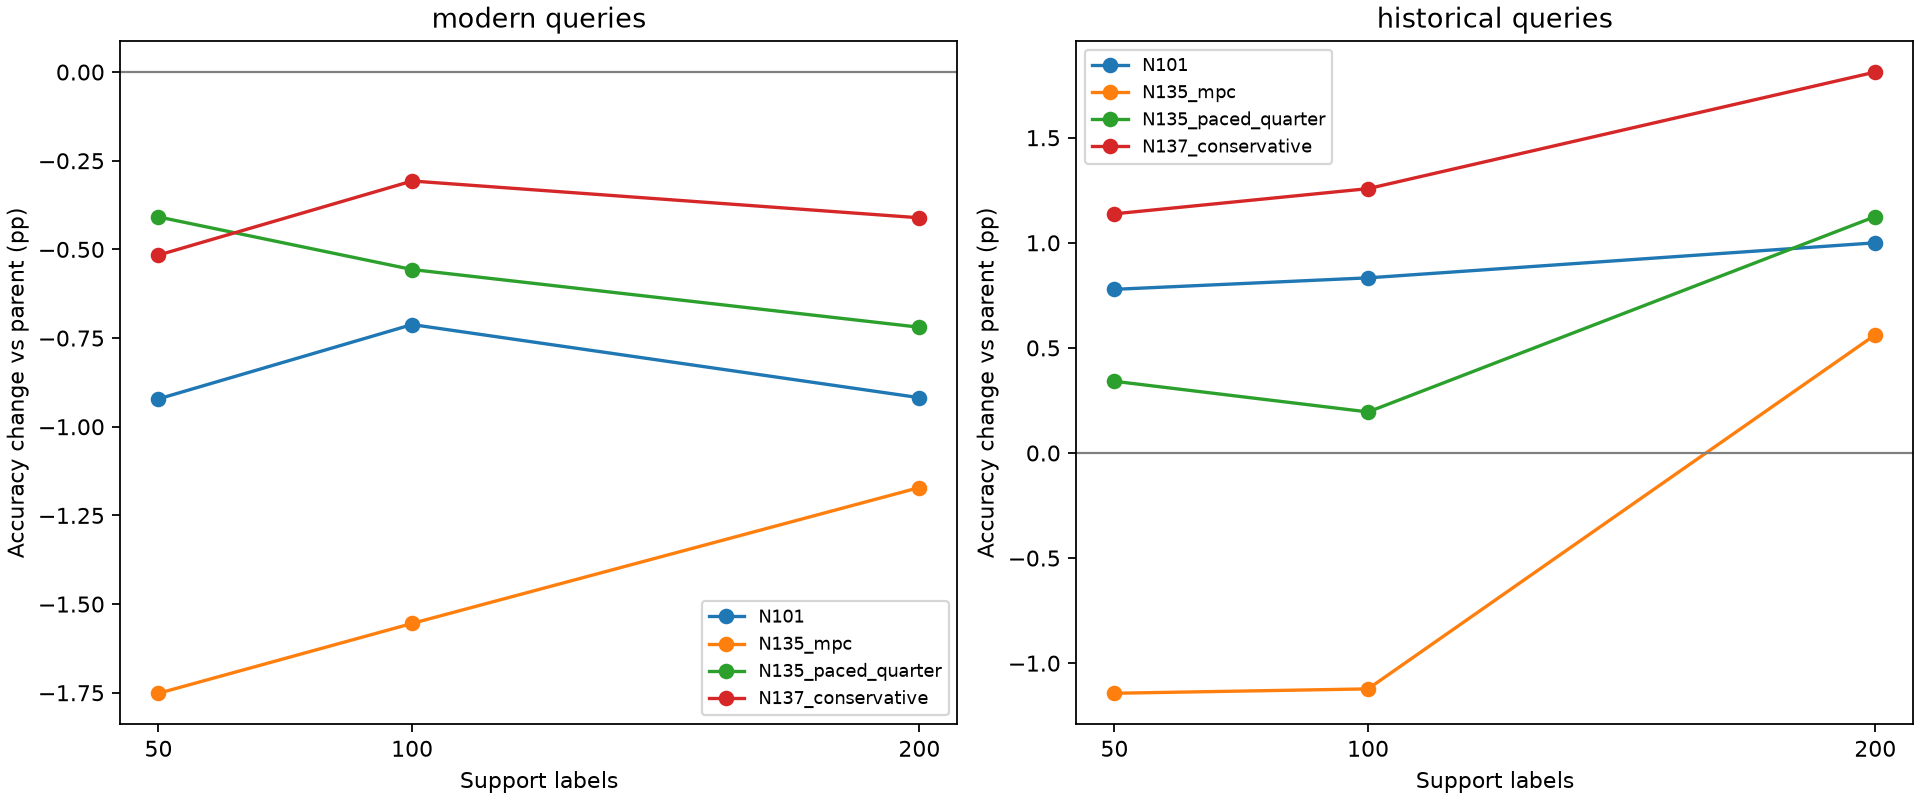

In [1]:
from pathlib import Path
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\probe-retention\\20261103-n139\\label-curves.png'))


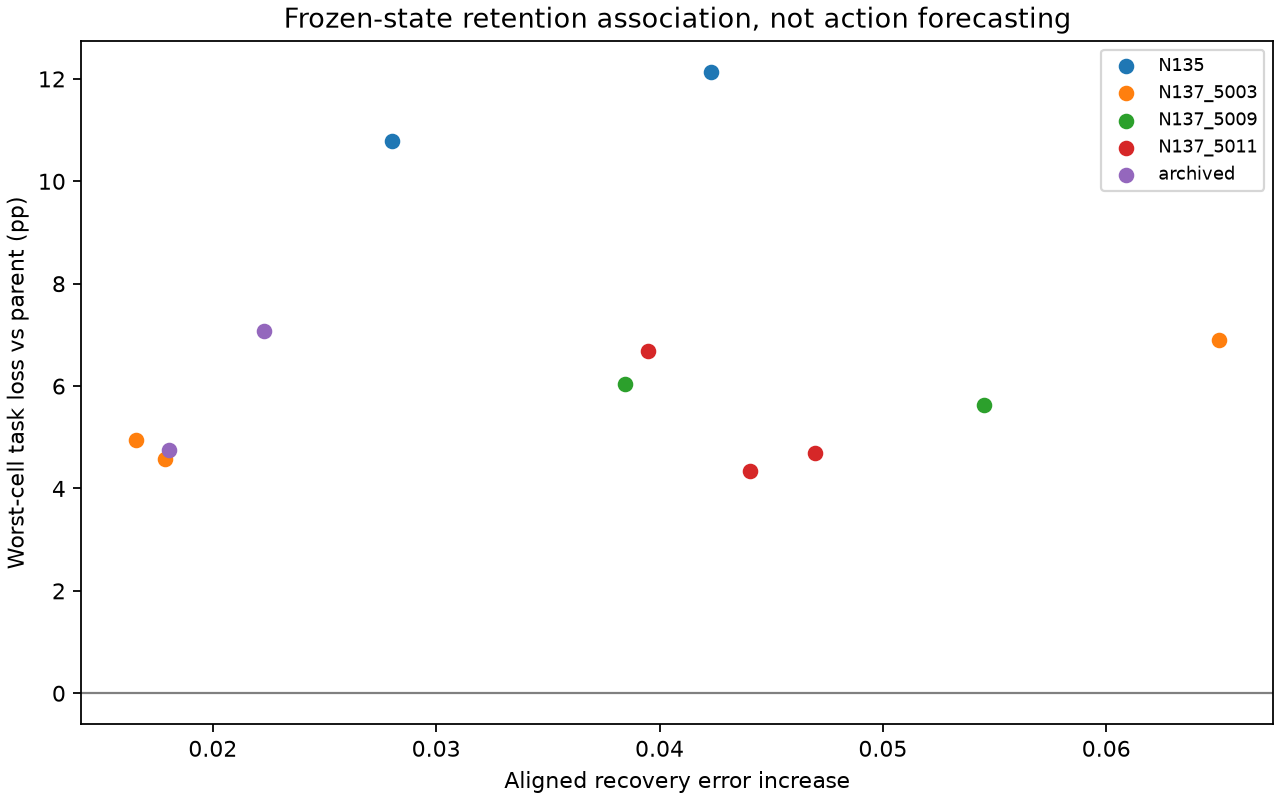

In [2]:
from pathlib import Path
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\probe-retention\\20261103-n139\\retention.png'))
